# matplotlib ------ 课后练✋

In [4]:
%matplotlib inline
import matplotlib as mpl
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd

## 练习1：航班乘客变化分析
* 分析年度乘客总量变化情况（折线图）
* 分析乘客在一年中各月份的分布（柱状图）

### 1.分析年度乘客总量变化情况（折线图）

In [5]:
# ----从U盘读取csv（用r""原始字符串防止反斜杠转义）----
file_path = r"G:\研一数据仓库\实验一\flights.csv"
data = pd.read_csv(file_path)
print(data.head())
print("数据形状：", data.shape)

   year     month  passengers
0  1949   January         112
1  1949  February         118
2  1949     March         132
3  1949     April         129
4  1949       May         121
数据形状： (144, 3)


In [10]:
data = sns.load_dataset("flights")
data.head()
# 年份，月份，乘客数

,year,month,passengers
0,1949,January,112
1,1949,February,118
2,1949,March,132
3,1949,April,129
4,1949,May,121


In [11]:
by_year_month = data.groupby(['year','month'])

# import numpy as np
# by_year_month_stats = data.groupby(['year','month']).agg({'passengers': [np.sum]}).unstack(0)

by_year_month_data = by_year_month.passengers.sum().unstack(1)
by_year_month_data

month,January,February,March,April,May,June,July,August,September,October,November,December
year,,,,,,,,,,,,
1949,112,118,132,129,121,135,148,148,136,119,104,118
1950,115,126,141,135,125,149,170,170,158,133,114,140
1951,145,150,178,163,172,178,199,199,184,162,146,166
1952,171,180,193,181,183,218,230,242,209,191,172,194
1953,196,196,236,235,229,243,264,272,237,211,180,201
1954,204,188,235,227,234,264,302,293,259,229,203,229
1955,242,233,267,269,270,315,364,347,312,274,237,278
1956,284,277,317,313,318,374,413,405,355,306,271,306
1957,315,301,356,348,355,422,465,467,404,347,305,336


In [12]:
total = by_year_month_data.sum(1)
total

year
1949    1520
1950    1676
1951    2042
1952    2364
1953    2700
1954    2867
1955    3408
1956    3939
1957    4421
1958    4572
1959    5140
1960    5714
dtype: int64

In [12]:
total = by_year_month_data.sum(1)
total

year
1949    1520
1950    1676
1951    2042
1952    2364
1953    2700
1954    2867
1955    3408
1956    3939
1957    4421
1958    4572
1959    5140
1960    5714
dtype: int64

In [12]:
total = by_year_month_data.sum(1)
total

year
1949    1520
1950    1676
1951    2042
1952    2364
1953    2700
1954    2867
1955    3408
1956    3939
1957    4421
1958    4572
1959    5140
1960    5714
dtype: int64

In [13]:
x = by_year_month_data.index
y = total.values

In [13]:
x = by_year_month_data.index
y = total.values

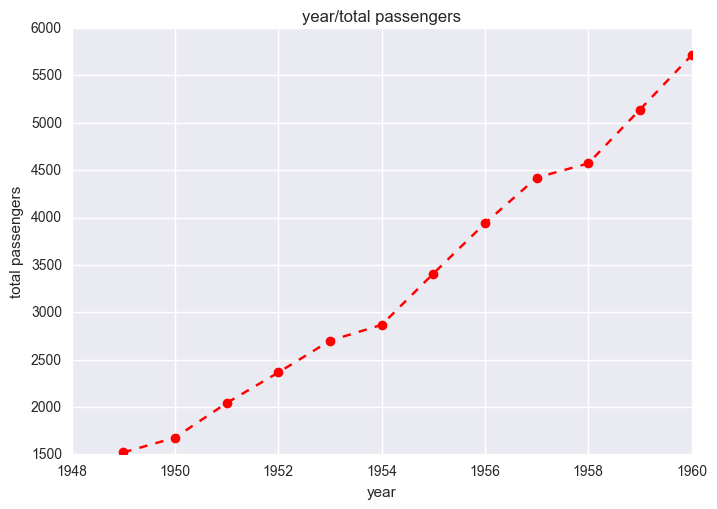

In [14]:
plt.plot(x,y,'ro--')
plt.xlabel('year')
plt.ylabel('total passengers')
plt.title('year/total passengers')

 ### 2.分析乘客在一年中各月份的分布（柱状图）

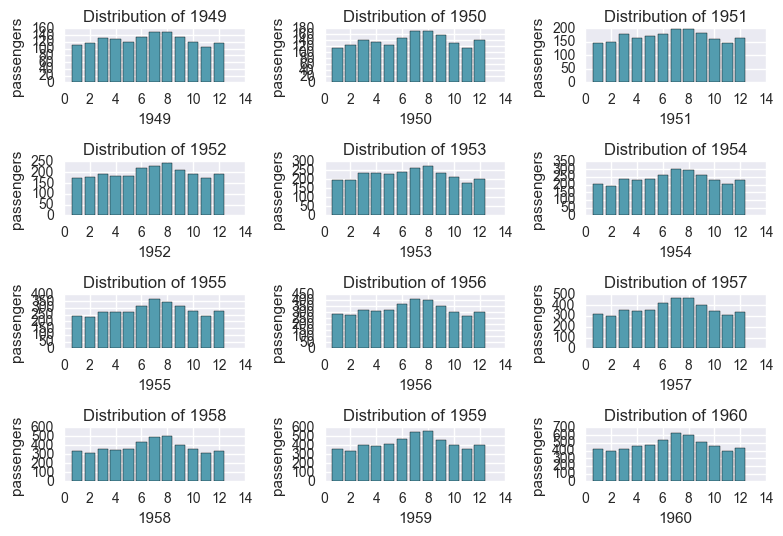

In [28]:
# 绘制堆叠的直方图

for i in range(1949,1961):

    x_data = range(1,13)
    y_data = by_year_month_data.loc[i].values

    data_name = '%s' % i
    data_color = '#539caf'
    x_label = '%s' % i
    y_label = 'passengers'
    title = 'Distribution of %s' % i
    
    ite = i -1948
    plt.subplot(4,3,ite)
    plt.bar(x_data, y_data, color = '#539caf', align = 'center')
    #http://matplotlib.org/api/pyplot_api.html?highlight=bar#matplotlib.pyplot.bar
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title)

plt.tight_layout()
plt.show()

## 练习2：鸢尾花花型尺寸分析
* 萼片（sepal）和花瓣（petal）的大小关系（散点图）
* 不同种类（species）鸢尾花萼片和花瓣的大小关系（分类散点子图）
* 不同种类鸢尾花萼片和花瓣大小的分布情况（柱状图或者箱式图）

In [39]:
data = sns.load_dataset("iris")
data.head()
# 萼片长度，萼片宽度，花瓣长度，花瓣宽度，种类

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


#### 萼片（sepal）和花瓣（petal）的大小关系（散点图）

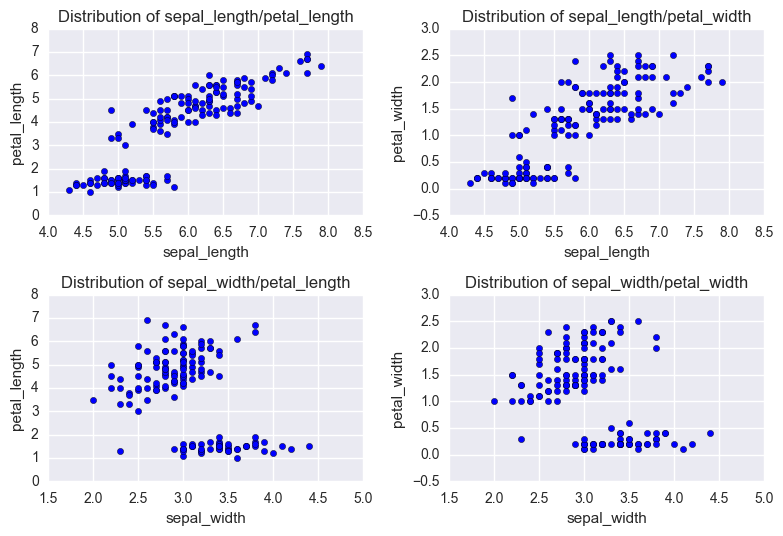

In [50]:
# your code

# 绘制散点图的函数
def scattergram(data, x_label, y_label, title, i):
    x = data[x_label]
    y = data[y_label]
    plt.subplot(2,2,i)
    res = plt.scatter(x,y)
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title)
    return res

#sepal_length/petal_length
# 绘图函数调用
res = scattergram(data
           , x_label = 'sepal_length'
           , y_label = 'petal_length'
           , title = 'Distribution of sepal_length/petal_length'
           , i = 1)

# #sepal_length/petal_width
res = scattergram(data
           , x_label = 'sepal_length'
           , y_label = 'petal_width'
           , title = 'Distribution of sepal_length/petal_width'
           , i = 2)

# #sepal_width/petal_length
res = scattergram(data
           , x_label = 'sepal_width'
           , y_label = 'petal_length'
           , title = 'Distribution of sepal_width/petal_length'
           , i =3)

# #sepal_width/petal_width
res = scattergram(data
           , x_label = 'sepal_width'
           , y_label = 'petal_width'
           , title = 'Distribution of sepal_width/petal_width'
           , i = 4)

plt.tight_layout()
plt.show()

#### 不同种类（species）鸢尾花萼片和花瓣的大小关系（分类散点子图）

In [194]:
species_data = data.set_index(['species'])
species_data.index.value_counts()

setosa        50
versicolor    50
virginica     50
Name: species, dtype: int64

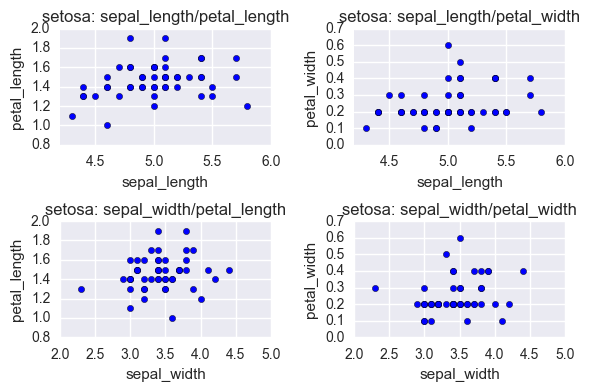

In [211]:
# setosa类
subdata11 = species_data.loc['setosa',('sepal_length','petal_length')]
plt.subplot(221)
x = subdata11['sepal_length']
y = subdata11['petal_length']
plt.scatter(x,y)
plt.xlabel('sepal_length')
plt.ylabel('petal_length')
plt.title('setosa: sepal_length/petal_length')

subdata12 = species_data.loc['setosa',('sepal_length','petal_width')]
plt.subplot(222)
x = subdata12['sepal_length']
y = subdata12['petal_width']
plt.scatter(x,y)
plt.xlabel('sepal_length')
plt.ylabel('petal_width')
plt.title('setosa: sepal_length/petal_width')

subdata21 = species_data.loc['setosa',('sepal_width','petal_length')]
plt.subplot(223)
x = subdata21['sepal_width']
y = subdata21['petal_length']
plt.scatter(x,y)
plt.xlabel('sepal_width')
plt.ylabel('petal_length')
plt.title('setosa: sepal_width/petal_length')

subdata22 = species_data.loc['setosa',('sepal_width','petal_width')]
plt.subplot(224)
x = subdata22['sepal_width']
y = subdata22['petal_width']
plt.scatter(x,y)
plt.xlabel('sepal_width')
plt.ylabel('petal_width')
plt.title('setosa: sepal_width/petal_width')

plt.tight_layout()
plt.show()

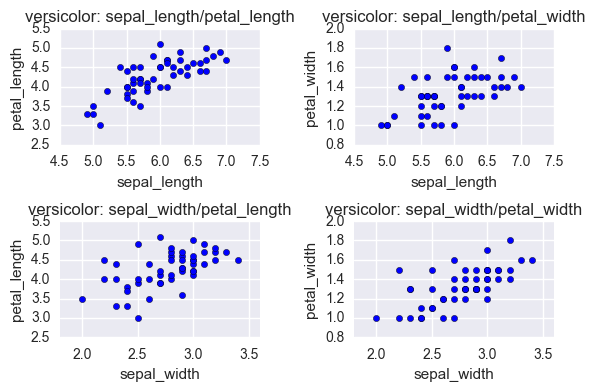

In [212]:
# versicolor类
subdata11 = species_data.loc['versicolor',('sepal_length','petal_length')]
plt.subplot(221)
x = subdata11['sepal_length']
y = subdata11['petal_length']
plt.scatter(x,y)
plt.xlabel('sepal_length')
plt.ylabel('petal_length')
plt.title('versicolor: sepal_length/petal_length')

subdata12 = species_data.loc['versicolor',('sepal_length','petal_width')]
plt.subplot(222)
x = subdata12['sepal_length']
y = subdata12['petal_width']
plt.scatter(x,y)
plt.xlabel('sepal_length')
plt.ylabel('petal_width')
plt.title('versicolor: sepal_length/petal_width')

subdata21 = species_data.loc['versicolor',('sepal_width','petal_length')]
plt.subplot(223)
x = subdata21['sepal_width']
y = subdata21['petal_length']
plt.scatter(x,y)
plt.xlabel('sepal_width')
plt.ylabel('petal_length')
plt.title('versicolor: sepal_width/petal_length')

subdata22 = species_data.loc['versicolor',('sepal_width','petal_width')]
plt.subplot(224)
x = subdata22['sepal_width']
y = subdata22['petal_width']
plt.scatter(x,y)
plt.xlabel('sepal_width')
plt.ylabel('petal_width')
plt.title('versicolor: sepal_width/petal_width')

plt.tight_layout()
plt.show()

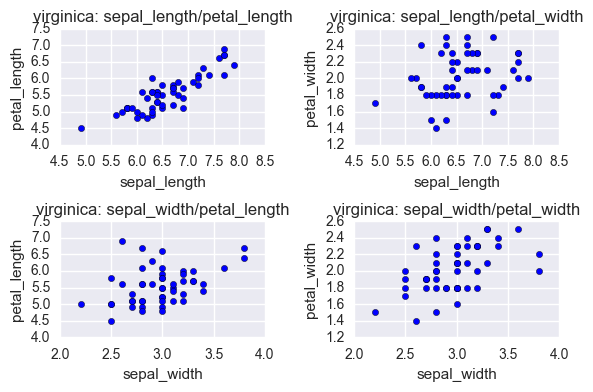

In [213]:
# virginica类
subdata11 = species_data.loc['virginica',('sepal_length','petal_length')]
plt.subplot(221)
x = subdata11['sepal_length']
y = subdata11['petal_length']
plt.scatter(x,y)
plt.xlabel('sepal_length')
plt.ylabel('petal_length')
plt.title('virginica: sepal_length/petal_length')

subdata12 = species_data.loc['virginica',('sepal_length','petal_width')]
plt.subplot(222)
x = subdata12['sepal_length']
y = subdata12['petal_width']
plt.scatter(x,y)
plt.xlabel('sepal_length')
plt.ylabel('petal_width')
plt.title('virginica: sepal_length/petal_width')

subdata21 = species_data.loc['virginica',('sepal_width','petal_length')]
plt.subplot(223)
x = subdata21['sepal_width']
y = subdata21['petal_length']
plt.scatter(x,y)
plt.xlabel('sepal_width')
plt.ylabel('petal_length')
plt.title('virginica: sepal_width/petal_length')

subdata22 = species_data.loc['virginica',('sepal_width','petal_width')]
plt.subplot(224)
x = subdata22['sepal_width']
y = subdata22['petal_width']
plt.scatter(x,y)
plt.xlabel('sepal_width')
plt.ylabel('petal_width')
plt.title('virginica: sepal_width/petal_width')

plt.tight_layout()
plt.show()

#### 不同种类鸢尾花萼片和花瓣大小的分布情况（柱状图或者箱式图）

In [52]:
species_data = data.set_index(['species'])
# species_data.index.value_counts()
species_data.head()

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.1,3.5,1.4,0.2
setosa,4.9,3.0,1.4,0.2
setosa,4.7,3.2,1.3,0.2
setosa,4.6,3.1,1.5,0.2
setosa,5.0,3.6,1.4,0.2


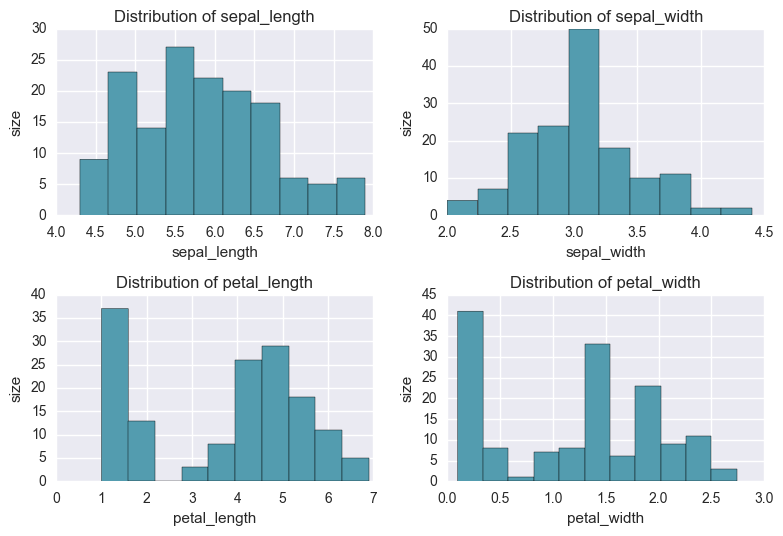

In [56]:
import numpy as np

# 归一化数据区间，对齐两个直方图的bins

#sepal_length
data = species_data['sepal_length']
data_name = 'sepal_length'
data_color = '#539caf'
x_label = 'sepal_length'
y_label = 'size'
title = 'Distribution of sepal_length'

max_nbins = 10
data_range = [min(data), max(data)]
binwidth = (data_range[1] - data_range[0]) / max_nbins
bins = np.arange(data_range[0], data_range[1] + binwidth, binwidth) # 生成直方图bins区间

plt.subplot(221)
plt.hist(data, bins = bins, color = data_color, alpha = 1, label = data_name)
plt.xlabel(x_label)
plt.ylabel(y_label)
plt.title(title)

#sepal_width
data = species_data['sepal_width']
data_name = 'sepal_width'
data_color = '#539caf'
x_label = 'sepal_width'
y_label = 'size'
title = 'Distribution of sepal_width'

max_nbins = 10
data_range = [min(data), max(data)]
binwidth = (data_range[1] - data_range[0]) / max_nbins
bins = np.arange(data_range[0], data_range[1] + binwidth, binwidth) # 生成直方图bins区间

plt.subplot(222)
plt.hist(data, bins = bins, color = data_color, alpha = 1, label = data_name)
plt.xlabel(x_label)
plt.ylabel(y_label)
plt.title(title)

#petal_length
data = species_data['petal_length']
data_name = 'petal_length'
data_color = '#539caf'
x_label = 'petal_length'
y_label = 'size'
title = 'Distribution of petal_length'

max_nbins = 10
data_range = [min(data), max(data)]
binwidth = (data_range[1] - data_range[0]) / max_nbins
bins = np.arange(data_range[0], data_range[1] + binwidth, binwidth) # 生成直方图bins区间

plt.subplot(223)
plt.hist(data, bins = bins, color = data_color, alpha = 1, label = data_name)
plt.xlabel(x_label)
plt.ylabel(y_label)
plt.title(title)

#petal_width
data = species_data['petal_width']
data_name = 'petal_width'
data_color = '#539caf'
x_label = 'petal_width'
y_label = 'size'
title = 'Distribution of petal_width'

max_nbins = 10
data_range = [min(data), max(data)]
binwidth = (data_range[1] - data_range[0]) / max_nbins
bins = np.arange(data_range[0], data_range[1] + binwidth, binwidth) # 生成直方图bins区间

plt.subplot(224)
plt.hist(data, bins = bins, color = data_color, alpha = 1, label = data_name)
plt.xlabel(x_label)
plt.ylabel(y_label)
plt.title(title)

plt.tight_layout()
plt.show()

## 练习3：餐厅小费情况分析
* 小费和总消费之间的关系（散点图）
* 男性顾客和女性顾客，谁更慷慨（分类箱式图）
* 抽烟与否是否会对小费金额产生影响（分类箱式图）
* 工作日和周末，什么时候顾客给的小费更慷慨（分类箱式图）
* 午饭和晚饭，哪一顿顾客更愿意给小费（分类箱式图）
* 就餐人数是否会对慷慨度产生影响（分类箱式图）
* 性别+抽烟的组合因素对慷慨度的影响（分组柱状图）

In [2]:
data = sns.load_dataset("tips")
data.head()
# 总消费，小费，性别，吸烟与否，就餐星期，就餐时间，就餐人数

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


### 1.小费和总消费之间的关系（散点图）

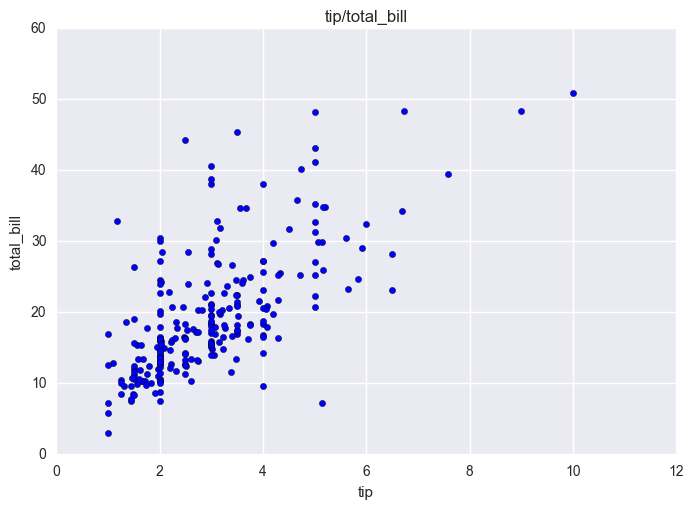

In [76]:
x = data['tip']
y = data['total_bill']
plt.scatter(x,y)
plt.xlabel('tip')
plt.ylabel('total_bill')
plt.title('tip/total_bill')

### 2.男性顾客和女性顾客，谁更慷慨（分类箱式图）

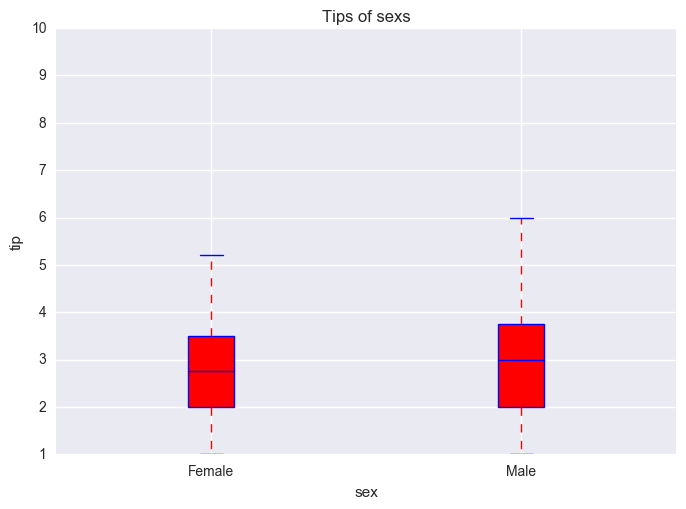

In [105]:
sexs = np.unique(data['sex'])
sex_data = []
for sex in sexs:
    sex_data.append(data[data['sex'] == sex]['tip'].values)

# 定义绘图函数
def boxplot(x_data, y_data, base_color, median_color, x_label, y_label, title):
    _, ax = plt.subplots()

    # 设置样式
    ax.boxplot(y_data
               # 箱子是否颜色填充
               , patch_artist = True
               # 中位数线颜色
               , medianprops = {'color': base_color}
               # 箱子颜色设置，color：边框颜色，facecolor：填充颜色
               , boxprops = {'color': base_color, 'facecolor': median_color}
               # 猫须颜色whisker
               , whiskerprops = {'color': median_color}
               # 猫须界限颜色whisker cap
               , capprops = {'color': base_color})

    # 箱图与x_data保持一致
    ax.set_xticklabels(x_data)
    ax.set_ylabel(y_label)
    ax.set_xlabel(x_label)
    ax.set_title(title)

# 调用绘图函数
boxplot(x_data = sexs
        , y_data = sex_data
        , base_color = 'b'
        , median_color = 'r'
        , x_label = 'sex'
        , y_label = 'tip'
        , title = 'Tips of sexs')

### 3.抽烟与否是否会对小费金额产生影响（分类箱式图）

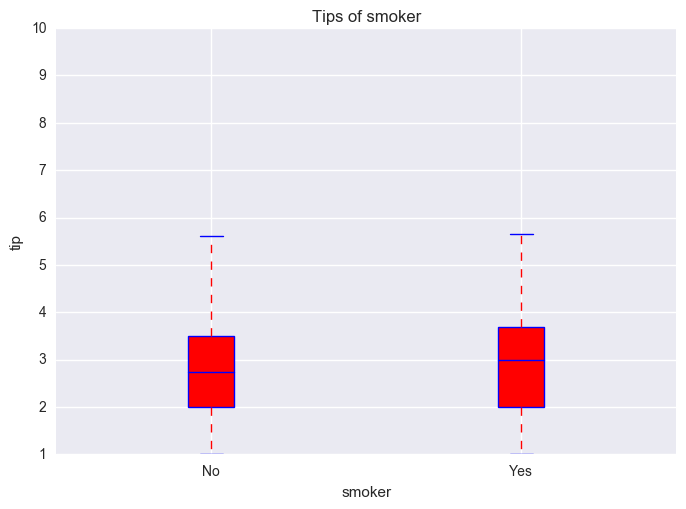

In [80]:
persons = np.unique(data['smoker'])
smoker_data = []
for person in persons:
    smoker_data.append(data[data['smoker'] == person]['tip'].values)

# 定义绘图函数
def boxplot(x_data, y_data, base_color, median_color, x_label, y_label, title):
    _, ax = plt.subplots()

    # 设置样式
    ax.boxplot(y_data
               # 箱子是否颜色填充
               , patch_artist = True
               # 中位数线颜色
               , medianprops = {'color': base_color}
               # 箱子颜色设置，color：边框颜色，facecolor：填充颜色
               , boxprops = {'color': base_color, 'facecolor': median_color}
               # 猫须颜色whisker
               , whiskerprops = {'color': median_color}
               # 猫须界限颜色whisker cap
               , capprops = {'color': base_color})

    # 箱图与x_data保持一致
    ax.set_xticklabels(x_data)
    ax.set_ylabel(y_label)
    ax.set_xlabel(x_label)
    ax.set_title(title)

# 调用绘图函数
boxplot(x_data = persons
        , y_data = smoker_data
        , base_color = 'b'
        , median_color = 'r'
        , x_label = 'smoker'
        , y_label = 'tip'
        , title = 'Tips of smoker')

### 4.工作日和周末，什么时候顾客给的小费更慷慨（分类箱式图）

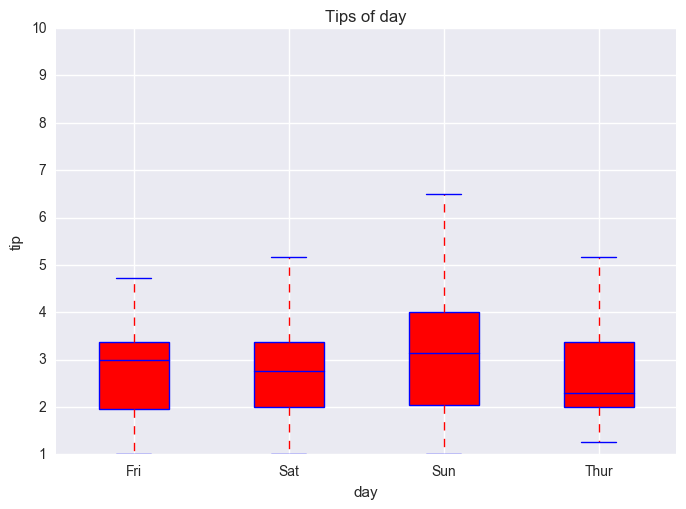

In [84]:
days = np.unique(data['day'])
day_data = []
for day in days:
    day_data.append(data[data['day'] == day]['tip'].values)

# 定义绘图函数
def boxplot(x_data, y_data, base_color, median_color, x_label, y_label, title):
    _, ax = plt.subplots()

    # 设置样式
    ax.boxplot(y_data
               # 箱子是否颜色填充
               , patch_artist = True
               # 中位数线颜色
               , medianprops = {'color': base_color}
               # 箱子颜色设置，color：边框颜色，facecolor：填充颜色
               , boxprops = {'color': base_color, 'facecolor': median_color}
               # 猫须颜色whisker
               , whiskerprops = {'color': median_color}
               # 猫须界限颜色whisker cap
               , capprops = {'color': base_color})

    # 箱图与x_data保持一致
    ax.set_xticklabels(x_data)
    ax.set_ylabel(y_label)
    ax.set_xlabel(x_label)
    ax.set_title(title)

# 调用绘图函数
boxplot(x_data = days
        , y_data = day_data
        , base_color = 'b'
        , median_color = 'r'
        , x_label = 'day'
        , y_label = 'tip'
        , title = 'Tips of day')

### 5.午饭和晚饭，哪一顿顾客更愿意给小费（分类箱式图）

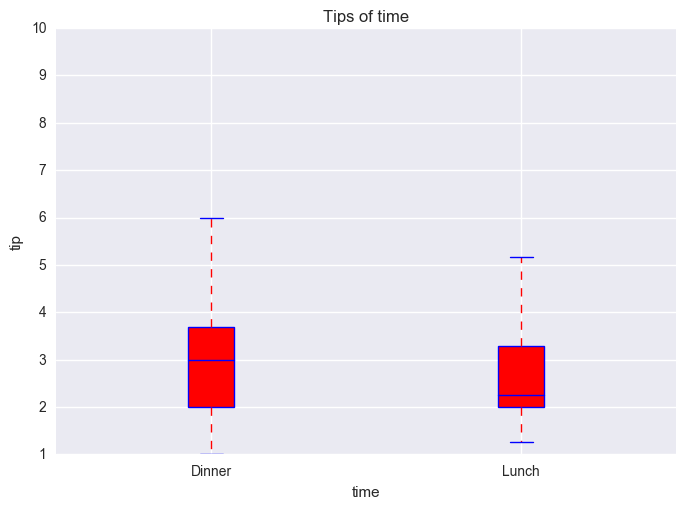

In [92]:
times = np.unique(data['time'])
time_data = []
for time in times:
    time_data.append(data[data['time'] == time]['tip'].values)

# 定义绘图函数
def boxplot(x_data, y_data, base_color, median_color, x_label, y_label, title):
    _, ax = plt.subplots()

    # 设置样式
    ax.boxplot(y_data
               # 箱子是否颜色填充
               , patch_artist = True
               # 中位数线颜色
               , medianprops = {'color': base_color}
               # 箱子颜色设置，color：边框颜色，facecolor：填充颜色
               , boxprops = {'color': base_color, 'facecolor': median_color}
               # 猫须颜色whisker
               , whiskerprops = {'color': median_color}
               # 猫须界限颜色whisker cap
               , capprops = {'color': base_color})

    # 箱图与x_data保持一致
    ax.set_xticklabels(x_data)
    ax.set_ylabel(y_label)
    ax.set_xlabel(x_label)
    ax.set_title(title)

# 调用绘图函数
boxplot(x_data = times
        , y_data = time_data
        , base_color = 'b'
        , median_color = 'r'
        , x_label = 'time'
        , y_label = 'tip'
        , title = 'Tips of time')

### 6.就餐人数是否会对慷慨度产生影响（分类箱式图）

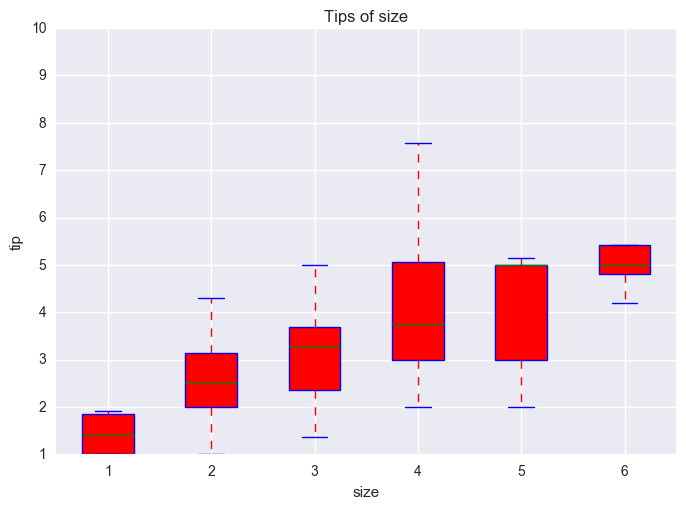

In [99]:
sizes = np.unique(data['size'])
size_data = []
for size in sizes:
    size_data.append(data[data['size'] == size]['tip'].values)

# 定义绘图函数
def boxplot(x_data, y_data, base_color, median_color, x_label, y_label, title):
    _, ax = plt.subplots()

    # 设置样式
    ax.boxplot(y_data
               # 箱子是否颜色填充
               , patch_artist = True
               # 中位数线颜色
               , medianprops = {'color': 'g'}
               # 箱子颜色设置，color：边框颜色，facecolor：填充颜色
               , boxprops = {'color': base_color, 'facecolor': median_color}
               # 猫须颜色whisker
               , whiskerprops = {'color': median_color}
               # 猫须界限颜色whisker cap
               , capprops = {'color': base_color})

    # 箱图与x_data保持一致
    ax.set_xticklabels(x_data)
    ax.set_ylabel(y_label)
    ax.set_xlabel(x_label)
    ax.set_title(title)

# 调用绘图函数
boxplot(x_data = sizes
        , y_data = size_data
        , base_color = 'b'
        , median_color = 'r'
        , x_label = 'size'
        , y_label = 'tip'
        , title = 'Tips of size')

### 7.性别+抽烟的组合因素对慷慨度的影响（分组柱状图）

In [334]:
data = sns.load_dataset("tips")
data.head()
# 总消费，小费，性别，吸烟与否，就餐星期，就餐时间，就餐人数

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [335]:
sexs = np.unique(data['sex'])
x1 = sexs
sex_data = []
for sex in sexs:
    sex_data.append(data[data['sex'] == sex]['tip'].values)
    
# sex_data_mean = []
# for i in range(len(sex_data)):
#     data_sum = 0
#     for j in range(len(sex_data[i])):
#         data_sum = data_sum + sex_data[i][j]
#     temp_data_mean = data_sum/len(sex_data[i])
#     sex_data_mean.append(temp_data_mean)
# y1 = sex_data_mean

sex_data_mean = []
for i in range(len(sex_data)):
    sex_data_mean.append(sex_data[i].sum(0)/len(sex_data[i]))
    
y1 = sex_data_mean

In [336]:
persons = np.unique(data['smoker'])
x2 = persons
smoker_data = []
for person in persons:
    smoker_data.append(data[data['smoker'] == person]['tip'].values)

# smoker_data_mean = []
# for i in range(len(smoker_data)):
#     data_sum = 0
#     for j in range(len(smoker_data[i])):
#         data_sum = data_sum + smoker_data[i][j]
#     temp_data_mean = data_sum/len(smoker_data[i])
#     smoker_data_mean.append(temp_data_mean)
# y2 = smoker_data_mean 

smoker_data_mean = []
for i in range(len(smoker_data)):
    smoker_data_mean.append(smoker_data[i].sum(0)/len(smoker_data[i]))
    
y2 = smoker_data_mean

<Container object of 2 artists>

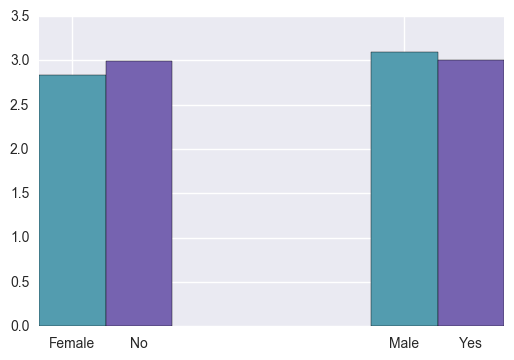

In [341]:
plt.xticks((0,1),(u'%s'%x1[0],u'%s'%x1[1]))
plt.bar((0,1), y1, color = '#539caf', width = 0.2, align = 'center')

# plt.xticks((0.2,1.2),(u'%s'%x2[0],u'%s'%x2[1]))
plt.text(0.2, -0.27, u'%s'%x2[0], ha='center', va= 'bottom',fontsize=10)
plt.text(1.2, -0.27, u'%s'%x2[1], ha='center', va= 'bottom',fontsize=10)

plt.bar((0.2,1.2), y2, color = '#7663b0', width = 0.2, align = 'center')


In [4]:
subdata = data[['sex','smoker','tip']].groupby(['sex','smoker']).mean()
subdata.head()

tip
sex    smoker          
Male   Yes     3.051167
       No      3.113402
Female Yes     2.931515
       No      2.773519

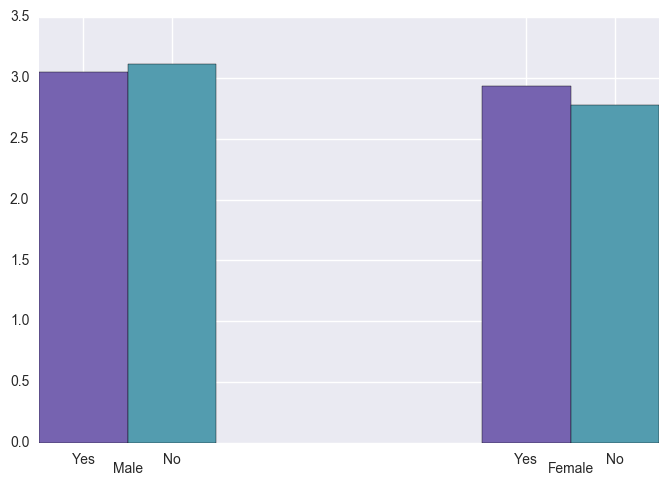

In [54]:
plt.xticks((0,0.2,1,1.2),('%s'%subdata.index[0][1],'%s'%subdata.index[1][1],'%s'%subdata.index[2][1],'%s'%subdata.index[3][1]))

plt.bar(0,subdata.values[0], color = '#7663b0', width = 0.2, align = 'center')
plt.bar(0.2,subdata.values[1], color = '#539caf', width = 0.2, align = 'center')
plt.bar(1,subdata.values[2], color = '#7663b0', width = 0.2, align = 'center')
plt.bar(1.2,subdata.values[3], color = '#539caf', width = 0.2, align = 'center')

plt.text(0.1, -0.27, u'%s'%subdata.index[0][0], ha='center', va= 'bottom',fontsize=10)
plt.text(1.1, -0.27, u'%s'%subdata.index[2][0], ha='center', va= 'bottom',fontsize=10)


## 练习4：泰坦尼克号海难幸存状况分析
* 不同仓位等级中幸存和遇难的乘客比例（堆积柱状图）
* 不同性别的幸存比例（堆积柱状图）
* 幸存和遇难乘客的票价分布（分类箱式图）
* 幸存和遇难乘客的年龄分布（分类箱式图）
* 不同上船港口的乘客仓位等级分布（分组柱状图）
* 幸存和遇难乘客堂兄弟姐妹的数量分布（分类箱式图）
* 幸存和遇难乘客父母子女的数量分布（分类箱式图）
* 单独乘船与否和幸存之间有没有联系（堆积柱状图或者分组柱状图）

In [342]:
data = sns.load_dataset("titanic")
data.head()
# 幸存与否，仓位等级，性别，年龄，堂兄弟姐妹数，父母子女数，票价，上船港口缩写，仓位等级，人员分类，是否成年男性，所在甲板，上船港口，是否幸存，是否单独乘船

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


### 1.不同仓位等级中幸存和遇难的乘客比例（堆积柱状图）

In [302]:
pclasses = np.unique(data['pclass'])
x = pclasses

pclass_data = []
for pclass in pclasses:
    pclass_data.append(data[data['pclass'] == pclass]['survived'].values)

survived_ratio = []
for i in range(len(pclass_data)):
    temp_ratio = float(pclass_data[i].sum(0))/len(pclass_data[i])
    ratio = float('%.2f' % temp_ratio)
    survived_ratio.append(ratio)
    
y1 = survived_ratio
print y1
y2 = [1-i for i in y1]
y2

[0.63, 0.47, 0.24]


[0.37, 0.53, 0.76]

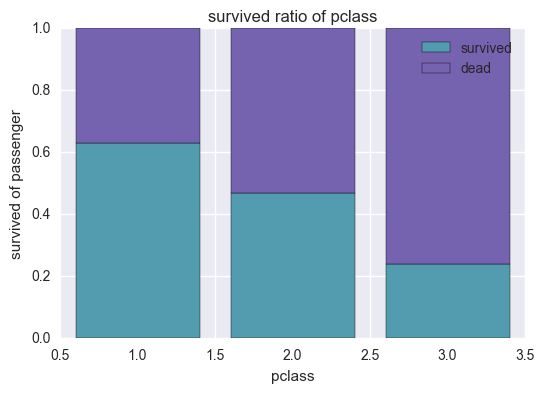

In [303]:
# 绘制堆积柱状图
def stackedbarplot(x_data, y_data_list, y_data_names, colors, x_label, y_label, title):
    _, ax = plt.subplots()
    # 循环绘制堆积柱状图
    for i in range(0, len(y_data_list)):
        if i == 0:
            ax.bar(x_data, y_data_list[i], color = colors[i], align = 'center', label = y_data_names[i])
        else:
            # 采用堆积的方式，除了第一个分类，后面的分类都从前一个分类的柱状图接着画
            # 用归一化保证最终累积结果为1
            ax.bar(x_data, y_data_list[i], color = colors[i], bottom = y_data_list[i - 1], align = 'center', label = y_data_names[i])
    ax.set_ylabel(y_label)
    ax.set_xlabel(x_label)
    ax.set_title(title)
    ax.legend(loc = 'upper right') # 设定图例位置

# 调用绘图函数
stackedbarplot(x_data = x
               , y_data_list = [y1, y2]
               , y_data_names = ['survived', 'dead']
               , colors = ['#539caf', '#7663b0']
               , x_label = 'pclass'
               , y_label = 'survived of passenger'
               , title = 'survived ratio of pclass')

### 2.不同性别的幸存比例（堆积柱状图）

In [312]:
sexs = np.unique(data['sex'])
x = sexs
x
# sex_data = []
# for sex in sexs:
#     sex_data.append(data[data['sex'] == sex]['survived'].values)
# len(sex_data)

array(['female', 'male'], dtype=object)

In [343]:
sexs = np.unique(data['sex'])
x = sexs

sex_data = []
for sex in sexs:
    sex_data.append(data[data['sex'] == sex]['survived'].values)

survived_ratio = []
for i in range(len(sex_data)):
    temp_ratio = float(sex_data[i].sum(0))/len(sex_data[i])
    ratio = float('%.2f' % temp_ratio)
    survived_ratio.append(ratio)
    
y1 = survived_ratio
print y1
y2 = [1-i for i in y1]
y2

[0.74, 0.19]


[0.26, 0.81]

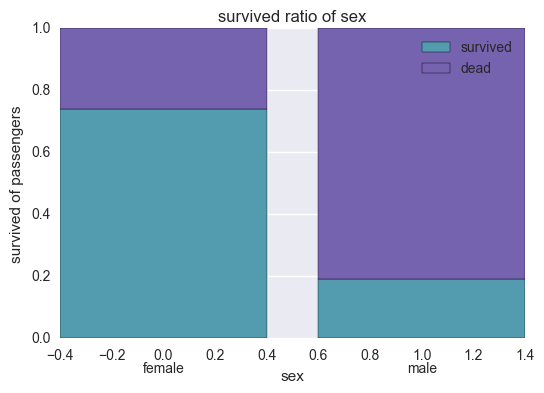

In [351]:
# 绘制堆积柱状图
def stackedbarplot(x_data, y_data_list, y_data_names, colors, x_label, y_label, title):
    _, ax = plt.subplots()
    # 循环绘制堆积柱状图
    for i in range(0, len(y_data_list)):
        if i == 0:
            ax.bar(x_data, y_data_list[i], color = colors[i], align = 'center', label = y_data_names[i])
        else:
            # 采用堆积的方式，除了第一个分类，后面的分类都从前一个分类的柱状图接着画
            # 用归一化保证最终累积结果为1
            ax.bar(x_data, y_data_list[i], color = colors[i], bottom = y_data_list[i - 1], align = 'center', label = y_data_names[i])
    ax.set_ylabel(y_label)
    ax.set_xlabel(x_label)
    ax.set_title(title)
    ax.legend(loc = 'upper right') # 设定图例位置
    ax.text(0, -0.12, u'%s'%x[0], ha='center', va= 'bottom',fontsize=10)
    ax.text(1, -0.12, u'%s'%x[1], ha='center', va= 'bottom',fontsize=10)
    
# 调用绘图函数
stackedbarplot(x_data = (0,1)
               , y_data_list = [y1, y2]
               , y_data_names = ['survived', 'dead']
               , colors = ['#539caf', '#7663b0']
               , x_label = 'sex'
               , y_label = 'survived of passengers'
               , title = 'survived ratio of sex')

### 3.幸存和遇难乘客的票价分布（分类箱式图）

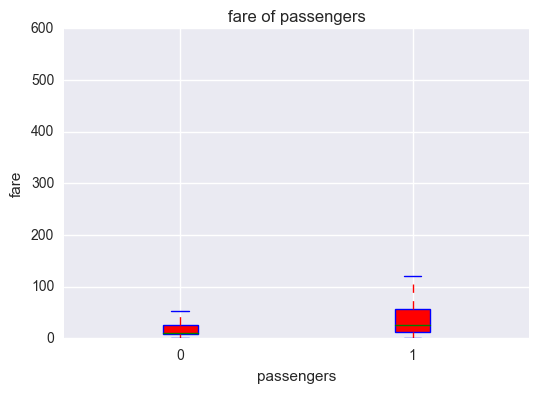

In [364]:
passengers = np.unique(data['survived'])
fare_data = []
for passenger in passengers:
    fare_data.append(data[data['survived'] == passenger]['fare'].values)

# 定义绘图函数
def boxplot(x_data, y_data, base_color, median_color, x_label, y_label, title):
    _, ax = plt.subplots()

    # 设置样式
    ax.boxplot(y_data
               # 箱子是否颜色填充
               , patch_artist = True
               # 中位数线颜色
               , medianprops = {'color': 'g'}
               # 箱子颜色设置，color：边框颜色，facecolor：填充颜色
               , boxprops = {'color': base_color, 'facecolor': median_color}
               # 猫须颜色whisker
               , whiskerprops = {'color': median_color}
               # 猫须界限颜色whisker cap
               , capprops = {'color': base_color})

    # 箱图与x_data保持一致
    ax.set_xticklabels(x_data)
    ax.set_ylabel(y_label)
    ax.set_xlabel(x_label)
    ax.set_title(title)

# 调用绘图函数
boxplot(x_data = passengers
        , y_data = fare_data
        , base_color = 'b'
        , median_color = 'r'
        , x_label = 'passengers'
        , y_label = 'fare'
        , title = 'fare of passengers')

### 4.幸存和遇难乘客的年龄分布（分类箱式图）

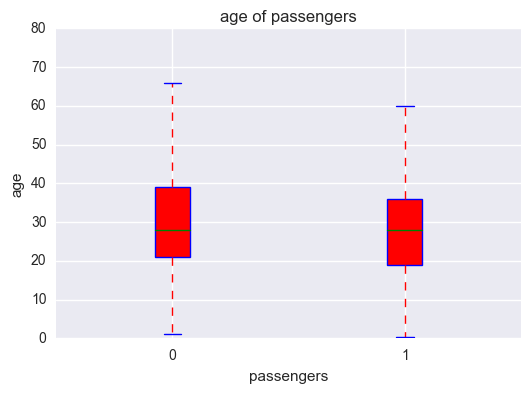

In [389]:
temp_data = data.loc[:,('survived','age')]
data = temp_data.dropna(axis=0,how='any')

passengers = np.unique(data['survived'])
age_data = []
for passenger in passengers:
    age_data.append(data[data['survived'] == passenger]['age'].values)

# 定义绘图函数
def boxplot(x_data, y_data, base_color, median_color, x_label, y_label, title):
    _, ax = plt.subplots()

    # 设置样式
    ax.boxplot(y_data
               # 箱子是否颜色填充
               , patch_artist = True
               # 中位数线颜色
               , medianprops = {'color': 'g'}
               # 箱子颜色设置，color：边框颜色，facecolor：填充颜色
               , boxprops = {'color': base_color, 'facecolor': median_color}
               # 猫须颜色whisker
               , whiskerprops = {'color': median_color}
               # 猫须界限颜色whisker cap
               , capprops = {'color': base_color})

    # 箱图与x_data保持一致
    ax.set_xticklabels(x_data)
    ax.set_ylabel(y_label)
    ax.set_xlabel(x_label)
    ax.set_title(title)

# 调用绘图函数
boxplot(x_data = passengers
        , y_data = age_data
        , base_color = 'b'
        , median_color = 'r'
        , x_label = 'passengers'
        , y_label = 'age'
        , title = 'age of passengers')

### 5.不同上船港口的乘客仓位等级分布（分组柱状图）

In [3]:
data = sns.load_dataset("titanic")
data.head()
# 幸存与否，仓位等级，性别，年龄，堂兄弟姐妹数，父母子女数，票价，上船港口缩写，仓位等级，人员分类，是否成年男性，所在甲板，上船港口，是否幸存，是否单独乘船

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


([<matplotlib.axis.XTick at 0xce09db0>,
 <a list of 3 Text xticklabel objects>)

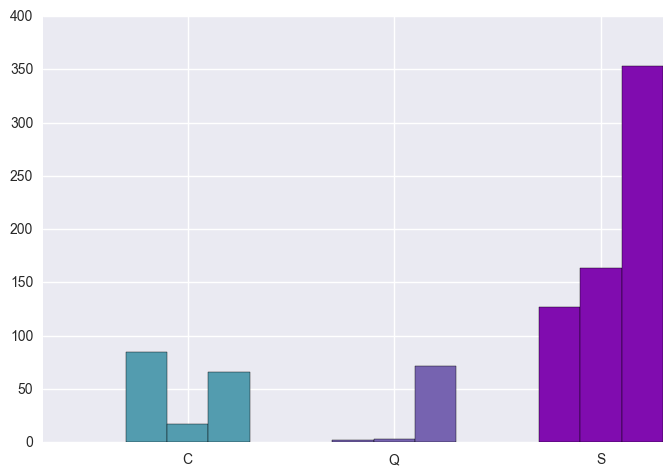

In [7]:
import numpy as np
temp_data = data.loc[:,('embarked','pclass')]
data = temp_data.dropna(axis=0,how='any')

ports = np.unique(data['embarked'])
x = ports

port_data = []
for port in ports:
    port_data.append(data[data['embarked'] == port]['pclass'].values)


port_data_pclass = [[],[],[]]  
for i in range(len(port_data)):
    count_1 = 0
    count_2 = 0
    count_3 = 0
    for j in range(len(port_data[i])):
        if port_data[i][j] == 1:
            count_1 += 1
        elif port_data[i][j] == 2:
            count_2 += 1
        elif port_data[i][j] == 3:
            count_3 += 1
    port_data_pclass[i] = [count_1, count_2, count_3]
       
y = port_data_pclass

plt.bar((0,0.2,0.4), y[0], color = '#539caf', width = 0.2, align = 'center')
plt.bar((1,1.2,1.4), y[1], color = '#7663b0', width = 0.2, align = 'center')
plt.bar((2,2.2,2.4), y[2], color = '#800caf', width = 0.2, align = 'center')

plt.xticks((0.2,1.2,2.2),(u'%s'%x[0],u'%s'%x[1],u'%s'%x[2]))

### 6.幸存和遇难乘客堂兄弟姐妹的数量分布（分类箱式图）

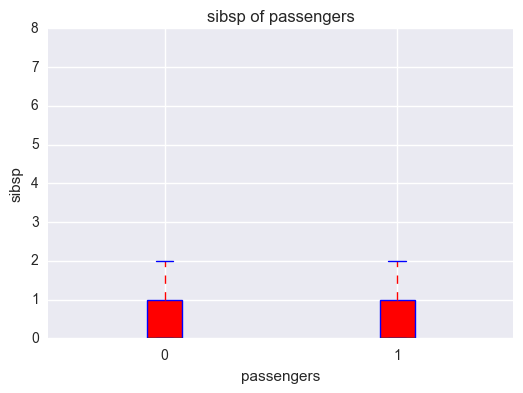

In [440]:
temp_data = data.loc[:,('survived','sibsp')]
data = temp_data.dropna(axis=0,how='any')

passengers = np.unique(data['survived'])
sibsp_data = []
for passenger in passengers:
    sibsp_data.append(data[data['survived'] == passenger]['sibsp'].values)

# 定义绘图函数
def boxplot(x_data, y_data, base_color, median_color, x_label, y_label, title):
    _, ax = plt.subplots()

    # 设置样式
    ax.boxplot(y_data
               # 箱子是否颜色填充
               , patch_artist = True
               # 中位数线颜色
               , medianprops = {'color': 'g'}
               # 箱子颜色设置，color：边框颜色，facecolor：填充颜色
               , boxprops = {'color': base_color, 'facecolor': median_color}
               # 猫须颜色whisker
               , whiskerprops = {'color': median_color}
               # 猫须界限颜色whisker cap
               , capprops = {'color': base_color})

    # 箱图与x_data保持一致
    ax.set_xticklabels(x_data)
    ax.set_ylabel(y_label)
    ax.set_xlabel(x_label)
    ax.set_title(title)

# 调用绘图函数
boxplot(x_data = passengers
        , y_data = sibsp_data
        , base_color = 'b'
        , median_color = 'r'
        , x_label = 'passengers'
        , y_label = 'sibsp'
        , title = 'sibsp of passengers')

### 7.幸存和遇难乘客父母子女的数量分布（分类箱式图）

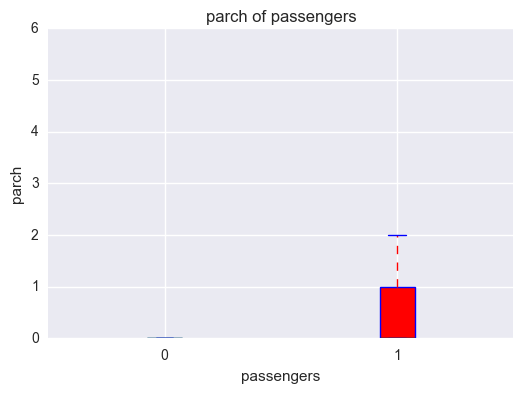

In [445]:
temp_data = data.loc[:,('survived','parch')]
data = temp_data.dropna(axis=0,how='any')

passengers = np.unique(data['survived'])
parch_data = []
for passenger in passengers:
    parch_data.append(data[data['survived'] == passenger]['parch'].values)

# 定义绘图函数
def boxplot(x_data, y_data, base_color, median_color, x_label, y_label, title):
    _, ax = plt.subplots()

    # 设置样式
    ax.boxplot(y_data
               # 箱子是否颜色填充
               , patch_artist = True
               # 中位数线颜色
               , medianprops = {'color': 'g'}
               # 箱子颜色设置，color：边框颜色，facecolor：填充颜色
               , boxprops = {'color': base_color, 'facecolor': median_color}
               # 猫须颜色whisker
               , whiskerprops = {'color': median_color}
               # 猫须界限颜色whisker cap
               , capprops = {'color': base_color})

    # 箱图与x_data保持一致
    ax.set_xticklabels(x_data)
    ax.set_ylabel(y_label)
    ax.set_xlabel(x_label)
    ax.set_title(title)

# 调用绘图函数
boxplot(x_data = passengers
        , y_data = parch_data
        , base_color = 'b'
        , median_color = 'r'
        , x_label = 'passengers'
        , y_label = 'parch'
        , title = 'parch of passengers')

### 8.单独乘船与否和幸存之间有没有联系（堆积柱状图或者分组柱状图）

In [446]:
data = sns.load_dataset("titanic")
data.head()
# 幸存与否，仓位等级，性别，年龄，堂兄弟姐妹数，父母子女数，票价，上船港口缩写，仓位等级，人员分类，是否成年男性，所在甲板，上船港口，是否幸存，是否单独乘船

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


([<matplotlib.axis.XTick at 0x14bdf870>,
 <a list of 2 Text xticklabel objects>)

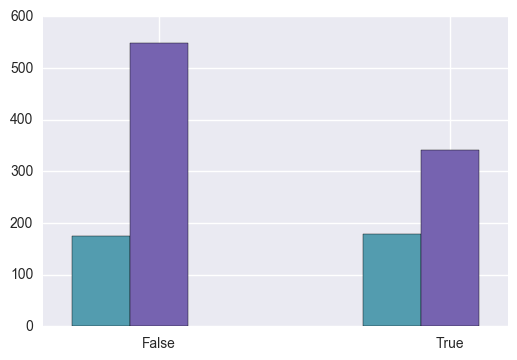

In [448]:
temp_data = data.loc[:,('survived','alone')]
data = temp_data.dropna(axis=0,how='any')

alone_states = np.unique(data['alone'])
x = alone_states

alone_state_data = []
for alone_state in alone_states:
    alone_state_data.append(data[data['alone'] == alone_state]['survived'].values)

count_1 = 0
count_2 = 0
alone_data_survived = [[],[]]  
for i in range(len(alone_state_data)):
    for j in range(len(alone_state_data[i])):
        if alone_state_data[i][j] == 0:
            count_1 += 1
        elif alone_state_data[i][j] == 1:
            count_2 += 1
    alone_data_survived[i] = [count_1, count_2]
       
y = alone_data_survived

plt.bar((0,1), y[0], color = '#539caf', width = 0.2, align = 'center')
plt.bar((0.2,1.2), y[1], color = '#7663b0', width = 0.2, align = 'center')

plt.xticks((0.2,1.2),(u'%s'%x[0],u'%s'%x[1]))